# Figure 5b: salinity section during the collapsed period, 8xCO2

Colors: change in zonal-mean salinity, years 2250-2349 minus years 750-849. Contours: mean salinity over years
800-2300. The green box marks 60-65N, upper 100 m.

The zonal means cover the Atlantic and GIN Seas on the native model grid, as area-weighted averages in 1-degree
latitude bins.

Input: `SALT_section_atlGIN_8x.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common
import cmocean as cm
from matplotlib import patches

matplotlib.rc('font', size=14)

In [2]:
section = xr.open_dataset(common.data_path('SALT_section_atlGIN_8x.nc'))
depth = -section.z_t / 100  # z_t is in cm, positive down

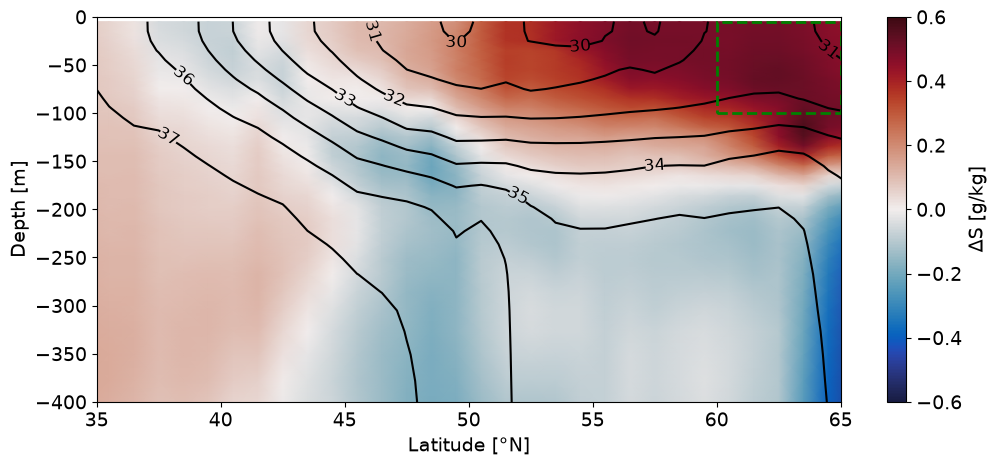

In [3]:
change_limit = 0.6  # color limit [g/kg]

plt.subplots(figsize=(12, 5))
p = plt.pcolormesh(section.lat, depth, np.ma.masked_invalid(section.salt_change), vmin=-change_limit, vmax=change_limit,
                   cmap=cm.cm.balance, shading='gouraud')
contours = plt.contour(section.lat, depth, section.salt_mean, colors='black', levels=np.arange(28, 38, 1))
plt.clabel(contours, inline=True, fontsize=12, inline_spacing=0)
plt.colorbar(p, label='ΔS [g/kg]')
plt.xlim([35, 65])
plt.ylim([-400, 0])
plt.xlabel('Latitude [°N]')
plt.ylabel('Depth [m]')
plt.gca().add_patch(patches.Rectangle((60, -100), 5, 95, linewidth=2, edgecolor='green', facecolor='none', zorder=5,
                                      linestyle='--'))
plt.savefig(common.figure_path('fig05b_salinity_section.png'), dpi=150, bbox_inches='tight')
plt.show()